# CNN Dog–Cat Classification

**Objective:** Classify images as cats or dogs using a Convolutional Neural Network (CNN).

**Concepts:** Image preprocessing, convolution, pooling, model training, and classification metrics.

**Tools:** Python, TensorFlow/Keras, NumPy, Matplotlib, Scikit-learn.

In [1]:
import os
import random
import zipfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Configuration
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 16

print("TensorFlow:", tf.__version__)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Setup completed successfully.")

TensorFlow: 2.21.0
Image size: (128, 128)
Batch size: 16
Setup completed successfully.


In [3]:
import urllib.request
import zipfile
from pathlib import Path

DATA_URL = (
    "https://download.mlcc.google.com/"
    "mledu-datasets/cats_and_dogs_filtered.zip"
)

zip_path = Path("/content/cats_and_dogs_filtered.zip")
DATASET_DIR = Path("/content/cats_and_dogs_filtered")

print("Downloading dataset...")

urllib.request.urlretrieve(DATA_URL, zip_path)

print("Download complete. Extracting...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "validation"

print("\nDataset extracted successfully!")

for split_name, split_dir in [
    ("Training source", TRAIN_DIR),
    ("Held-out test source", TEST_DIR)
]:
    print(f"\n{split_name}:")
    for class_name in ["cats", "dogs"]:
        count = sum(
            1 for p in (split_dir / class_name).iterdir()
            if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )
        print(f"{class_name}: {count} images")

Download complete. Extracting...

Dataset extracted successfully!

Training source:
cats: 1000 images
dogs: 1000 images

Held-out test source:
cats: 500 images
dogs: 500 images


### Dataset Preparation

The dataset contains 1,500 cat images and 1,500 dog images. We will reserve 20% of the training source for validation and keep the separate test source untouched until final evaluation.

In [4]:
# Load training and validation datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    str(TRAIN_DIR),
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    str(TRAIN_DIR),
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

# Load the separate held-out test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    str(TEST_DIR),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="binary"
)

class_names = train_ds.class_names

print("\nClass names:", class_names)
print("Training images:", len(train_ds.file_paths))
print("Validation images:", len(val_ds.file_paths))
print("Test images:", len(test_ds.file_paths))

Found 2000 files belonging to 2 classes.
Using 1600 files for training.
Found 2000 files belonging to 2 classes.
Using 400 files for validation.
Found 1000 files belonging to 2 classes.

Class names: ['cats', 'dogs']
Training images: 1600
Validation images: 400
Test images: 1000


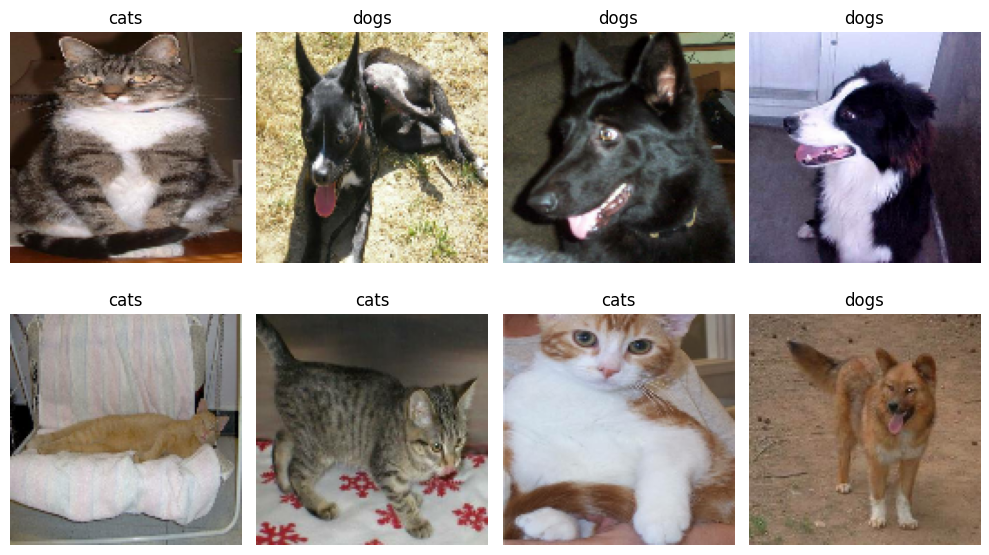

In [5]:
# Display sample images with their labels
plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))
        label_index = int(labels[i].numpy()[0])

        plt.title(class_names[label_index])
        plt.axis("off")

plt.tight_layout()
plt.show()

### CNN Architecture

The model uses three convolutional layers to learn image features, max-pooling layers to reduce spatial dimensions, and dense layers to classify images as cats or dogs.

In [6]:
# Build a CNN with exactly three convolutional layers
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    # Normalize pixel values from 0–255 to 0–1
    tf.keras.layers.Rescaling(1.0 / 255),

    # Convolutional layer 1
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolutional layer 2
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolutional layer 3
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

conv_layers = [
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Conv2D)
]

print("\nNumber of convolutional layers:", len(conv_layers))
assert len(conv_layers) == 3, "The model must contain exactly 3 Conv2D layers."
print("CNN architecture verified.")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)


Number of convolutional layers: 3
CNN architecture verified.


### Model Training

Train the CNN for up to 12 epochs. Early stopping monitors validation loss and restores the best-performing weights to help reduce overfitting.

In [7]:
# Improve input pipeline efficiency
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Stop training when validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Train the CNN
EPOCHS = 12

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/12
100/100 ━━━━━━━━━━━━━━━━━━━━ 33s 323ms/step - accuracy: 0.5119 - loss: 0.7035 - val_accuracy: 0.4550 - val_loss: 0.6979
Epoch 2/12
100/100 ━━━━━━━━━━━━━━━━━━━━ 40s 310ms/step - accuracy: 0.5800 - loss: 0.6832 - val_accuracy: 0.6025 - val_loss: 0.6665
Epoch 3/12
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 311ms/step - accuracy: 0.6250 - loss: 0.6483 - val_accuracy: 0.6700 - val_loss: 0.6107
Epoch 4/12
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 310ms/step - accuracy: 0.6762 - loss: 0.6111 - val_accuracy: 0.7100 - val_loss: 0.5781
Epoch 5/12
100/100 ━━━━━━━━━━━━━━━━━━━━ 31s 308ms/step - accuracy: 0.7150 - loss: 0.5708 - val_accuracy: 0.6750 - val_loss: 0.5769
Epoch 6/12
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 311ms/step - accuracy: 0.7344 - loss: 0.5165 - val_accuracy: 0.7350 - val_loss: 0.5898
Epoch 7/12
100/100 ━━━━━━━━━━━━━━━━━━━━ 31s 308ms/step - accuracy: 0.7875 - loss: 0.4512 - val_accuracy: 0.7050 - val_loss: 0.5724
Epoch 8/12
100/100 ━━━━━━━━━━━━━━━━━━━━ 42s 318ms/step - accuracy: 0.8281 - loss: 0

### Training Results

The model stopped early when validation loss stopped improving. The best weights were restored to reduce overfitting.

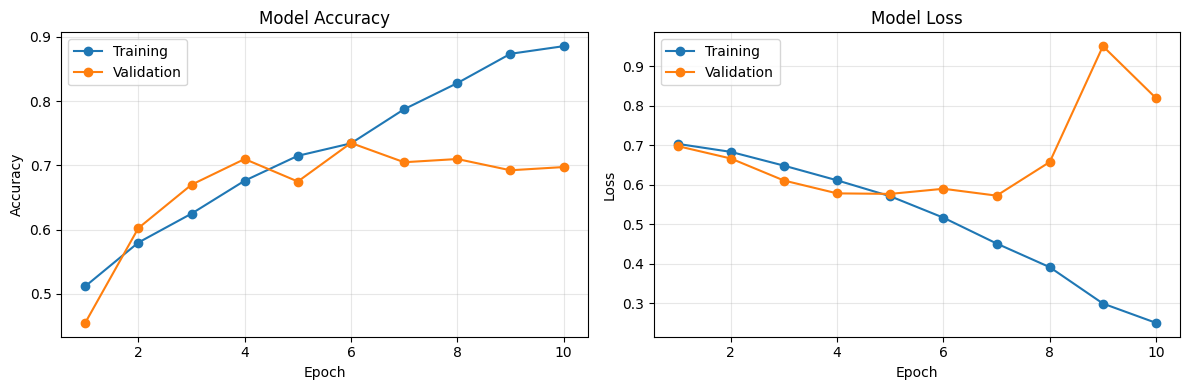

Epochs completed: 10
Best epoch by validation loss: 7
Best validation loss: 0.5724
Best validation accuracy: 0.7350


In [8]:
# Visualize training and validation performance
epochs_completed = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_completed, history.history["accuracy"], marker="o", label="Training")
plt.plot(epochs_completed, history.history["val_accuracy"], marker="o", label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_completed, history.history["loss"], marker="o", label="Training")
plt.plot(epochs_completed, history.history["val_loss"], marker="o", label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
print("Epochs completed:", len(history.history["loss"]))
print("Best epoch by validation loss:", best_epoch)
print(f"Best validation loss: {min(history.history['val_loss']):.4f}")
print(f"Best validation accuracy: {max(history.history['val_accuracy']):.4f}")

### Model Evaluation

Evaluate the restored model on the held-out test dataset using accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC.

In [9]:
# Predict probabilities for the held-out test images
y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_ds
]).astype(int)

y_prob = model.predict(test_ds, verbose=1).reshape(-1)
y_pred = (y_prob >= 0.5).astype(int)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_true, y_pred)
test_precision = precision_score(y_true, y_pred, zero_division=0)
test_recall = recall_score(y_true, y_pred, zero_division=0)
test_f1 = f1_score(y_true, y_pred, zero_division=0)
test_roc_auc = roc_auc_score(y_true, y_prob)

print("TEST SET RESULTS")
print("-" * 35)
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-score : {test_f1:.4f}")
print(f"ROC-AUC  : {test_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 140ms/step
TEST SET RESULTS
-----------------------------------
Accuracy : 0.7050
Precision: 0.6881
Recall   : 0.7500
F1-score : 0.7177
ROC-AUC  : 0.7544

Classification Report:
              precision    recall  f1-score   support

        cats       0.73      0.66      0.69       500
        dogs       0.69      0.75      0.72       500

    accuracy                           0.70      1000
   macro avg       0.71      0.71      0.70      1000
weighted avg       0.71      0.70      0.70      1000



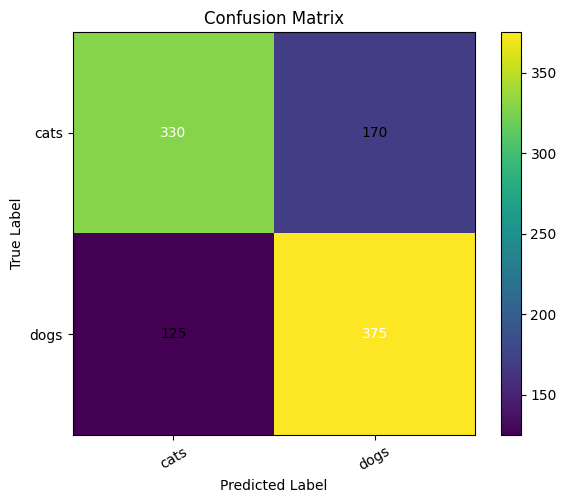

Confusion matrix:
[[330 170]
 [125 375]]


In [10]:
# Plot the confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar()

tick_positions = np.arange(len(class_names))
plt.xticks(tick_positions, class_names, rotation=30)
plt.yticks(tick_positions, class_names)

threshold = cm.max() / 2.0

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)

### Sample Predictions

Visualize test images alongside their predicted labels and confidence scores.

/tmp/ipykernel_798/496164371.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  true_index = int(labels[i].numpy())


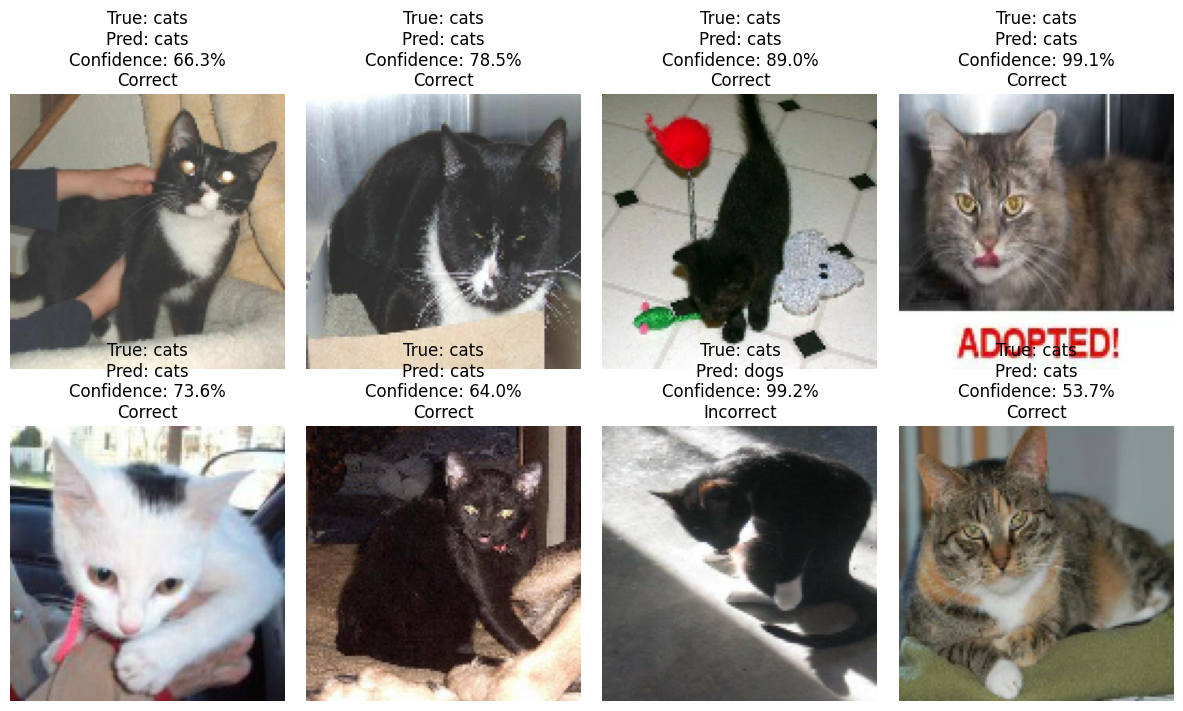

In [11]:
# Display eight test images with predicted labels
plt.figure(figsize=(12, 7))

for images, labels in test_ds.take(1):
    probabilities = model.predict(images, verbose=0).reshape(-1)

    for i in range(min(8, len(images))):
        true_index = int(labels[i].numpy())
        predicted_index = int(probabilities[i] >= 0.5)

        confidence = (
            probabilities[i]
            if predicted_index == 1
            else 1 - probabilities[i]
        )

        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        result = "Correct" if true_index == predicted_index else "Incorrect"

        plt.title(
            f"True: {class_names[true_index]}\n"
            f"Pred: {class_names[predicted_index]}\n"
            f"Confidence: {confidence:.1%}\n{result}"
        )
        plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
# Save the model with its restored best weights
MODEL_PATH = "/content/cnn_dog_cat_classifier.keras"

model.save(MODEL_PATH)

print("Model saved to:", MODEL_PATH)
print("Convolutional layers:", sum(
    isinstance(layer, tf.keras.layers.Conv2D)
    for layer in model.layers
))

Model saved to: /content/cnn_dog_cat_classifier.keras
Convolutional layers: 3


### Conclusion

The CNN classified cat and dog images with 70.50% test accuracy. The experiment demonstrates image preprocessing, convolutional feature extraction, model training, and classification evaluation. The training curves indicate overfitting, leaving scope for future improvement.